# Topological Photonic Crystals II — Domain Walls Excited by Circularly Polarized Sources

The edge states of notebook 01 carry a pseudospin (spin-Hall) or a valley index
(valley-Hall) that is locked to their propagation direction along the wall. A source that
emits only one handedness should therefore launch light in one direction only. This
notebook drives each of the four walls with a circularly polarized dipole and measures
how the emitted power splits between the two directions along the wall.

| wall | sample | source | drive |
|---|---|---|---|
| spin-Hall pillars (TM) | 20 clusters × (10 topological + 10 trivial) rows | Hx ± iHy at the centre of the topological cluster next to the wall | 0.457 c/a0 |
| spin-Hall holes (TE) | 20 clusters × (10 + 10) rows | Ex ± iEy, same position | 0.405 c/a0 |
| valley-Hall holes (TE) | 35 cells × (17 VPC1 + 17 VPC2) rows, bearded | Ex ± iEy in the centre of a bearded (large) hole | 0.2368 c/a |
| valley-Hall pillars (TM) | 35 cells × (17 + 17) rows, bearded | Hx ± iHy in the centre of a bearded (large) rod | 0.265 c/a |

The four samples have about the same physical size (a0 = √3 a). Each drive frequency lies
on the edge band inside the shared bulk gap (notebook 01); for the spin-Hall walls it is
on the lower branch, clear of the small anticrossing at kx = 0. S+ (S−) rotates
counterclockwise (clockwise) seen from +z (Meep's exp(−iωt) convention).

**Why those source positions.** The pseudospin of the spin-Hall modes is the angular
momentum of the field around a cluster centre, so the source sits at the centre of the
cluster next to the wall. For the valley-Hall walls the source must sit at a threefold
symmetric point of the lattice where the K-valley field has a phase vortex, *and* that
point must not be a twofold-rotation centre of the wall: a 180° rotation maps the wall onto
itself, reverses the propagation direction and leaves the handedness of the dipole
unchanged, so a source at such a centre emits equally both ways. The centre of a bearded
inclusion satisfies both (the position of He et al. 2019); Section 4 shows the
twofold-centre case for comparison.

**Model:** 2D Meep, CW source with a smooth turn-on, εd = 11.7 / air; resolution 32/a0
(spin-Hall) and 24/a (valley-Hall); the lattice continues through the PML along the wall,
and the rows are followed by background material and PML across it. Complex fields give
the time-averaged Poynting vector directly.

**Kernel:** `mp` conda env, run from `topological/notebooks/`. **Do not use "Run All."**

## 0. Setup

In [1]:
# Imports, style, the four runs.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle, Polygon

from pic_toolkit import style
from pic_toolkit.meep_sim import topological_pc as tp

style.apply_style()
DATA = Path.cwd().parent / "data" / "walls"
RUNS = {"spin_tm": 0.457, "spin_te": 0.405, "valley_te": 0.2368, "valley_tm": 0.265}
TITLE = {"spin_tm": "spin-Hall pillars (TM)", "spin_te": "spin-Hall holes (TE)",
         "valley_te": "valley-Hall holes (TE)", "valley_tm": "valley-Hall pillars (TM)"}
UNIT = {"spin_tm": "a0", "spin_te": "a0", "valley_te": "a", "valley_tm": "a"}

def load(kind, spin, source_at="default"):
    tag = "" if source_at == "default" else f"_{source_at}"
    return dict(np.load(DATA / f"{kind}_f{RUNS[kind]:.4f}_s{'p' if spin > 0 else 'm'}{tag}.npz"))

## 1. The walls and source positions

Zoom around each source: inclusions (rods or holes), the wall (dashed) and the source (★).
Spin-Hall: topological crystal below the wall, trivial above. Valley-Hall: VPC1 above,
VPC2 below, the large inclusions facing each other across the wall.

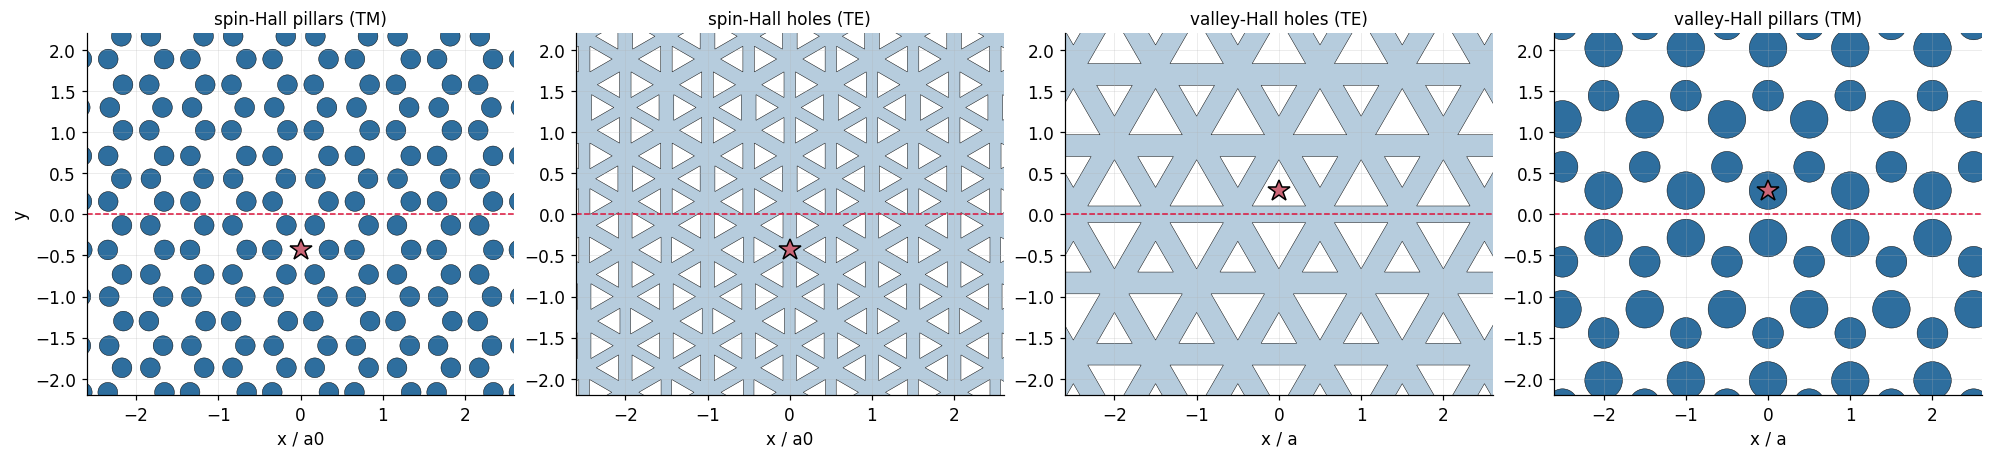

In [2]:
# Draw the inclusions near each source from the same generator the simulations use.
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), layout="constrained")
for ax, kind in zip(axes, tp.KINDS):
    (xs, ys), x_shift = tp.source_position(kind)
    bg = style.COLOR_STEEL if kind.endswith("_te") else "white"
    ax.add_patch(plt.Rectangle((-4, -4), 8, 8, color=bg, alpha=0.35 if bg != "white" else 1))
    for sh in tp.wall_shapes(kind, -4, 4, 4, x_shift):
        fc = "white" if kind.endswith("_te") else style.COLOR_STEEL
        if "circle" in sh:
            ax.add_patch(Circle(sh["circle"], sh["r"], fc=fc, ec="k", lw=0.3))
        else:
            ax.add_patch(Polygon(sh["poly"], fc=fc, ec="k", lw=0.3))
    ax.axhline(0, color=style.COLOR_ANNOTATION, ls="--", lw=1)
    ax.plot(xs, ys, marker="*", color=style.COLOR_ROSE, ms=15, mec="k")
    ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal")
    ax.set_title(TITLE[kind], fontsize=11); ax.set_xlabel(f"x / {UNIT[kind]}")
axes[0].set_ylabel("y")
fig.savefig(DATA.parent / "fig_wall_geometry.png", dpi=150, bbox_inches="tight")
plt.show()

> **STOP -- the eight runs (4 walls × S±) take 15–40 min each** (`scripts/run_walls.py`,
> cached in `data/walls/`). The cells below only read the cache.

## 2. Field distributions

For each wall and each handedness: the signed field that carries the polarization's
scalar component (Re Hz for TE, Re Ez for TM; red/blue) and the electric energy density
|E|² (|Ex|² + |Ey|² for TE, |Ez|² for TM; log scale). Both are normalized to their maximum
more than 1.5 lattice constants from the source, so the guided wave rather than the
source's near field sets the scale. Field maps are stored at every second grid point.

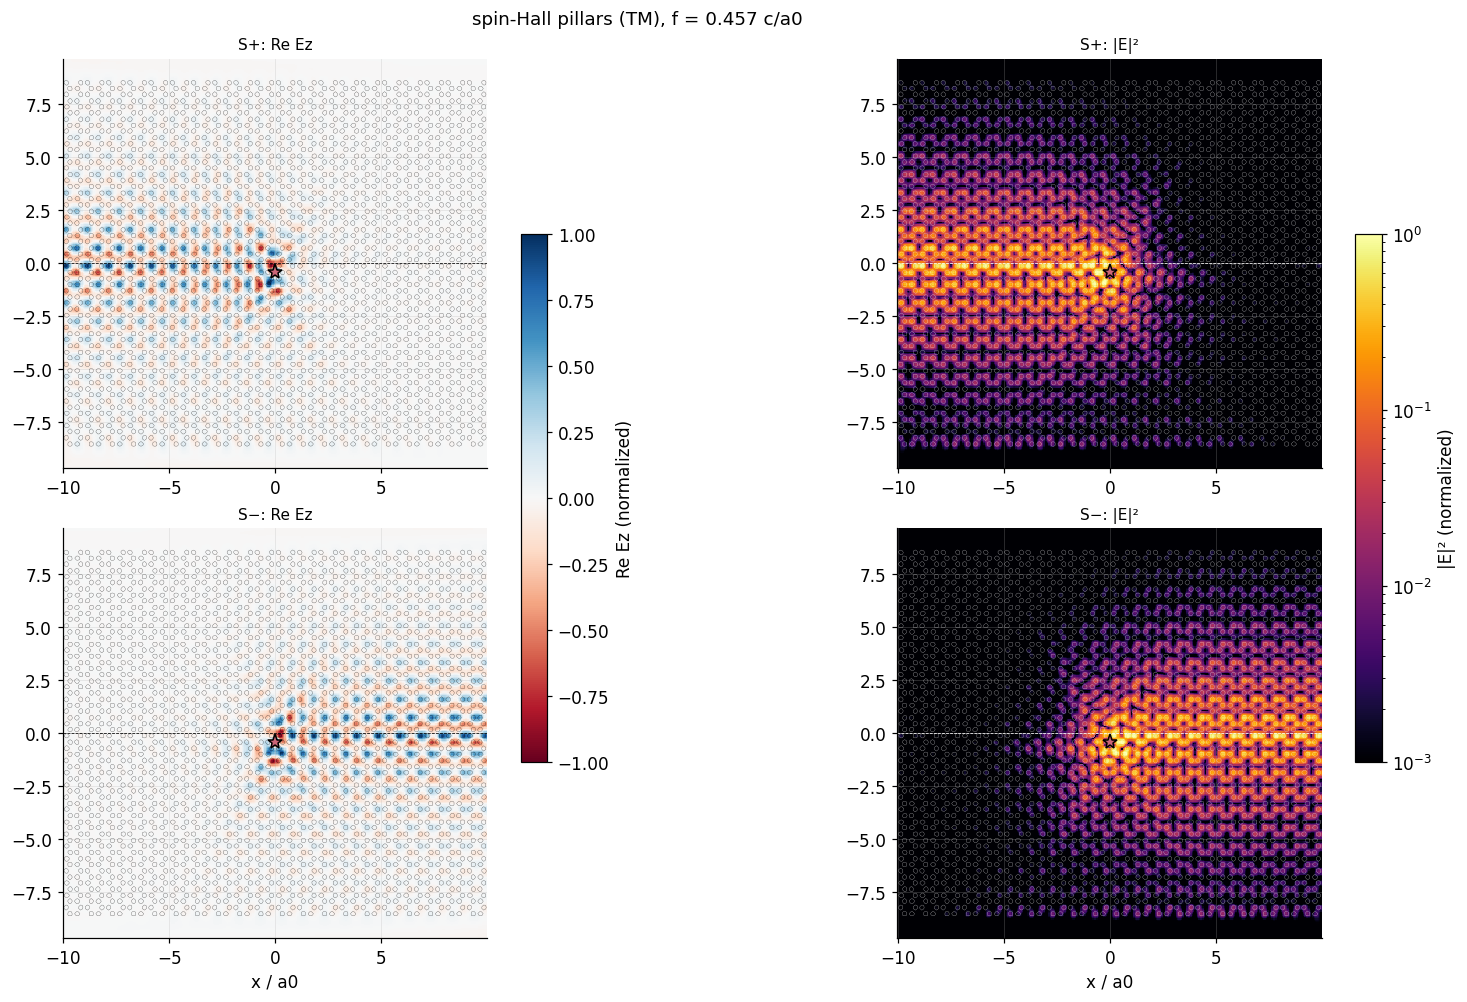

In [3]:
# One 2 x 2 figure per wall: rows S+ / S-, columns signed field / |E|^2.
def field_figure(kind):
    pol = tp.POLARIZATION[kind]
    comp = "hz" if pol == "TE" else "ez"
    fig, axes = plt.subplots(2, 2, figsize=(15, 9 if kind.startswith("spin") else 10), layout="constrained")
    for r, s in enumerate((+1, -1)):
        o = load(kind, s)
        x, y = o["x"], o["y"]
        ix = np.abs(x) <= o["n_x"] / 2
        iy = np.abs(y) <= o["n_rows"] * tp.ROW_H + o["pad_y"]
        X, Y = np.meshgrid(x[ix], y[iy], indexing="ij")
        far = np.hypot(X - o["src_xy"][0], Y - o["src_xy"][1]) > 1.5
        F = o[comp][np.ix_(ix, iy)]
        F = (F * np.exp(-1j * np.angle(F.flat[np.abs(F).argmax()]))).real
        E2 = o["E2"][np.ix_(ix, iy)]
        eps = o["eps"][np.ix_(ix, iy)]
        for c, (data, kw, lab) in enumerate((
                (F / np.abs(F[far]).max(), dict(cmap=style.CMAP_FIELD, vmin=-1, vmax=1), f"Re {comp[0].upper()}{comp[1]}"),
                (E2 / E2[far].max(), dict(cmap="inferno", norm=LogNorm(1e-3, 1)), "|E|²"))):
            ax = axes[r, c]
            im = ax.pcolormesh(x[ix], y[iy], data.T, shading="auto", rasterized=True, **kw)
            ax.contour(x[ix], y[iy], eps.T, levels=[6], colors="k" if c == 0 else "w", linewidths=0.15)
            ax.axhline(0, color="k" if c == 0 else "w", lw=0.5, ls="--")
            ax.plot(*o["src_xy"], "*", color=style.COLOR_ROSE, ms=10, mec="k")
            ax.set_aspect("equal")
            ax.set_title(f"{'S+' if s > 0 else 'S−'}: {lab}", fontsize=10)
            if r == 1:
                ax.set_xlabel(f"x / {UNIT[kind]}")
            if r == 0:
                fig.colorbar(im, ax=axes[:, c], shrink=0.6, label=lab + " (normalized)")
    fig.suptitle(f"{TITLE[kind]}, f = {RUNS[kind]} c/{UNIT[kind]}", fontsize=12)
    fig.savefig(DATA.parent / f"fig_wall_fields_{kind}.png", dpi=130, bbox_inches="tight")
    plt.show()

field_figure("spin_tm")

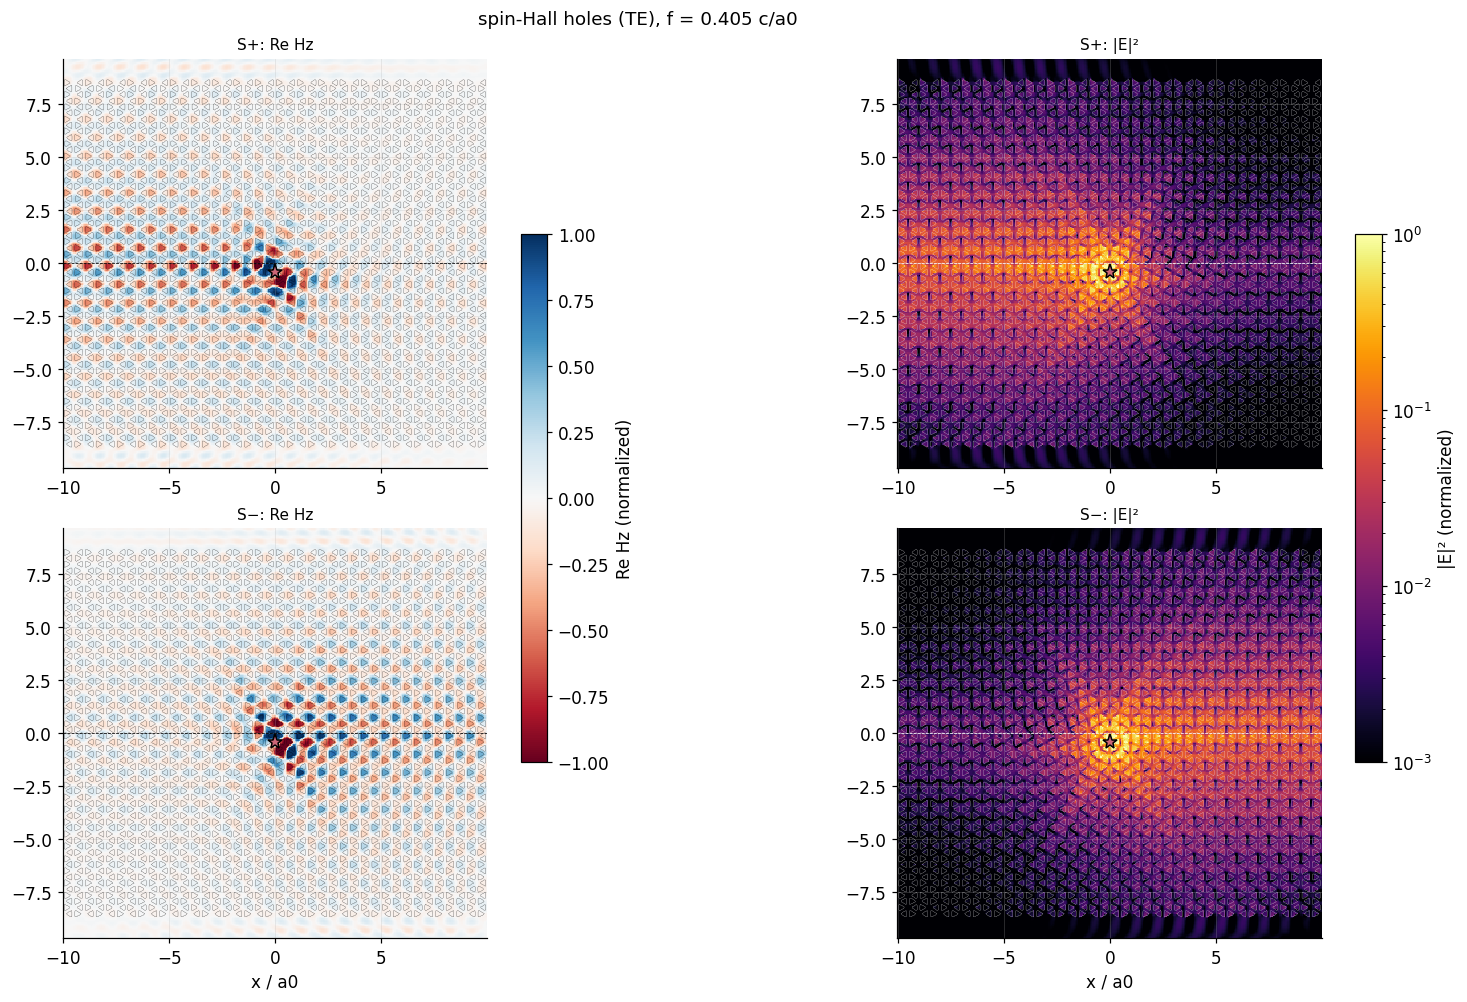

In [4]:
field_figure("spin_te")

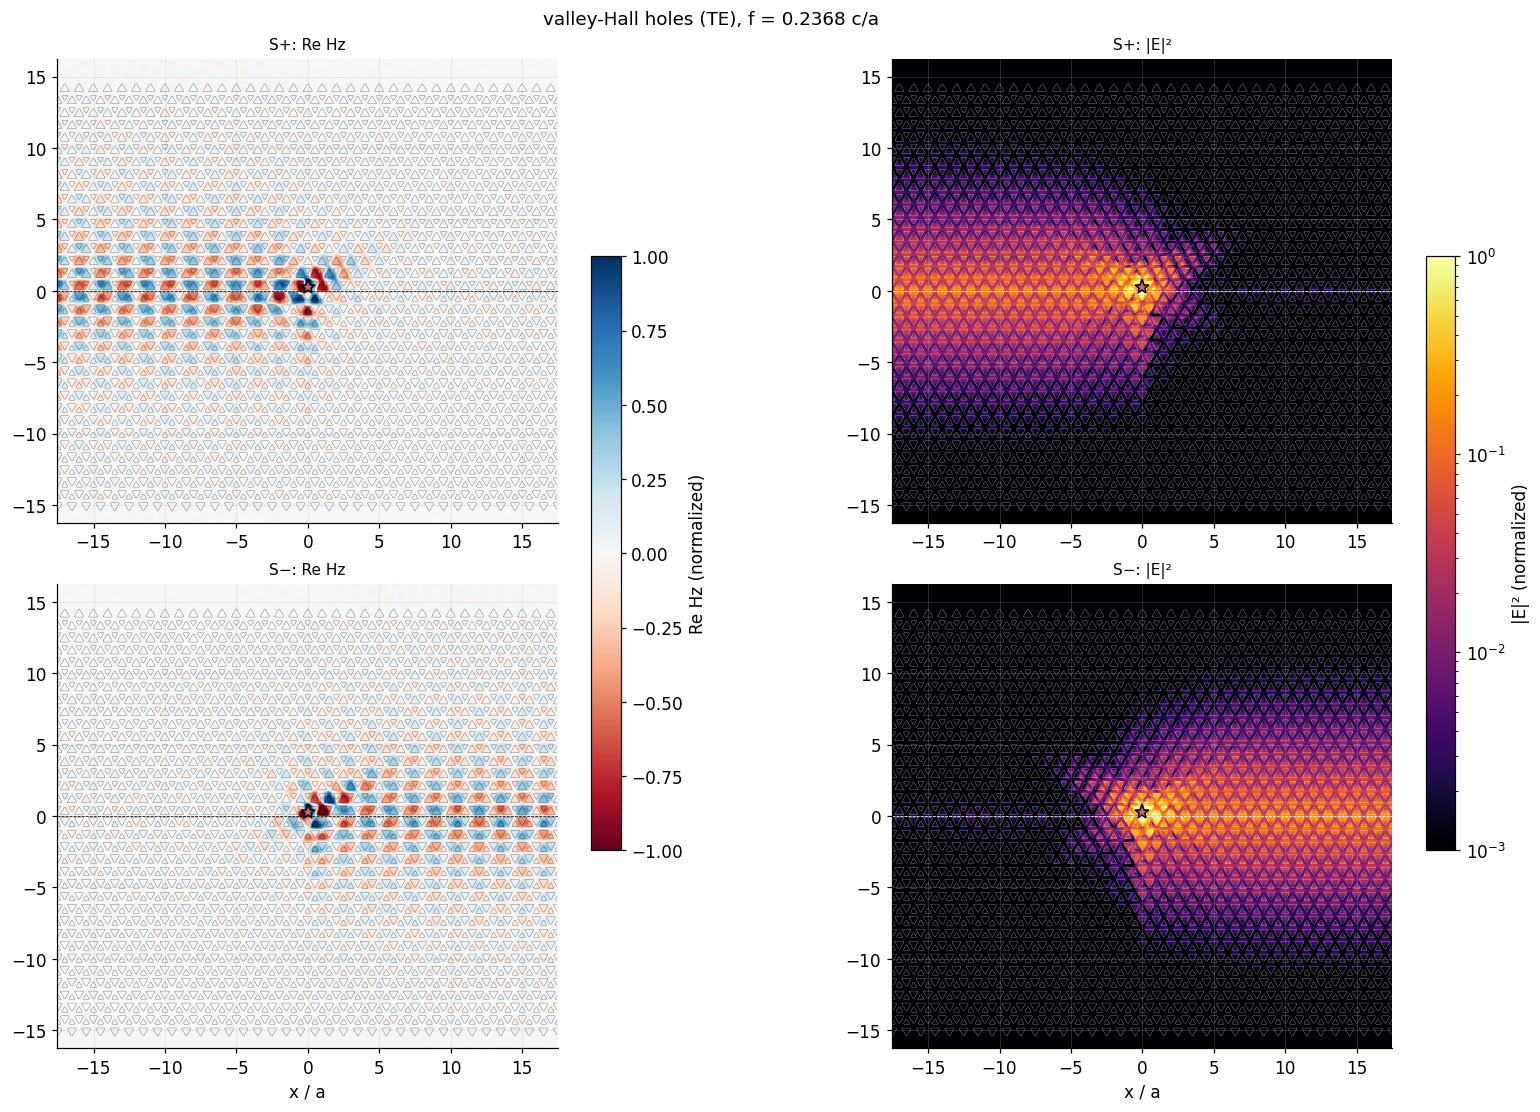

In [5]:
field_figure("valley_te")

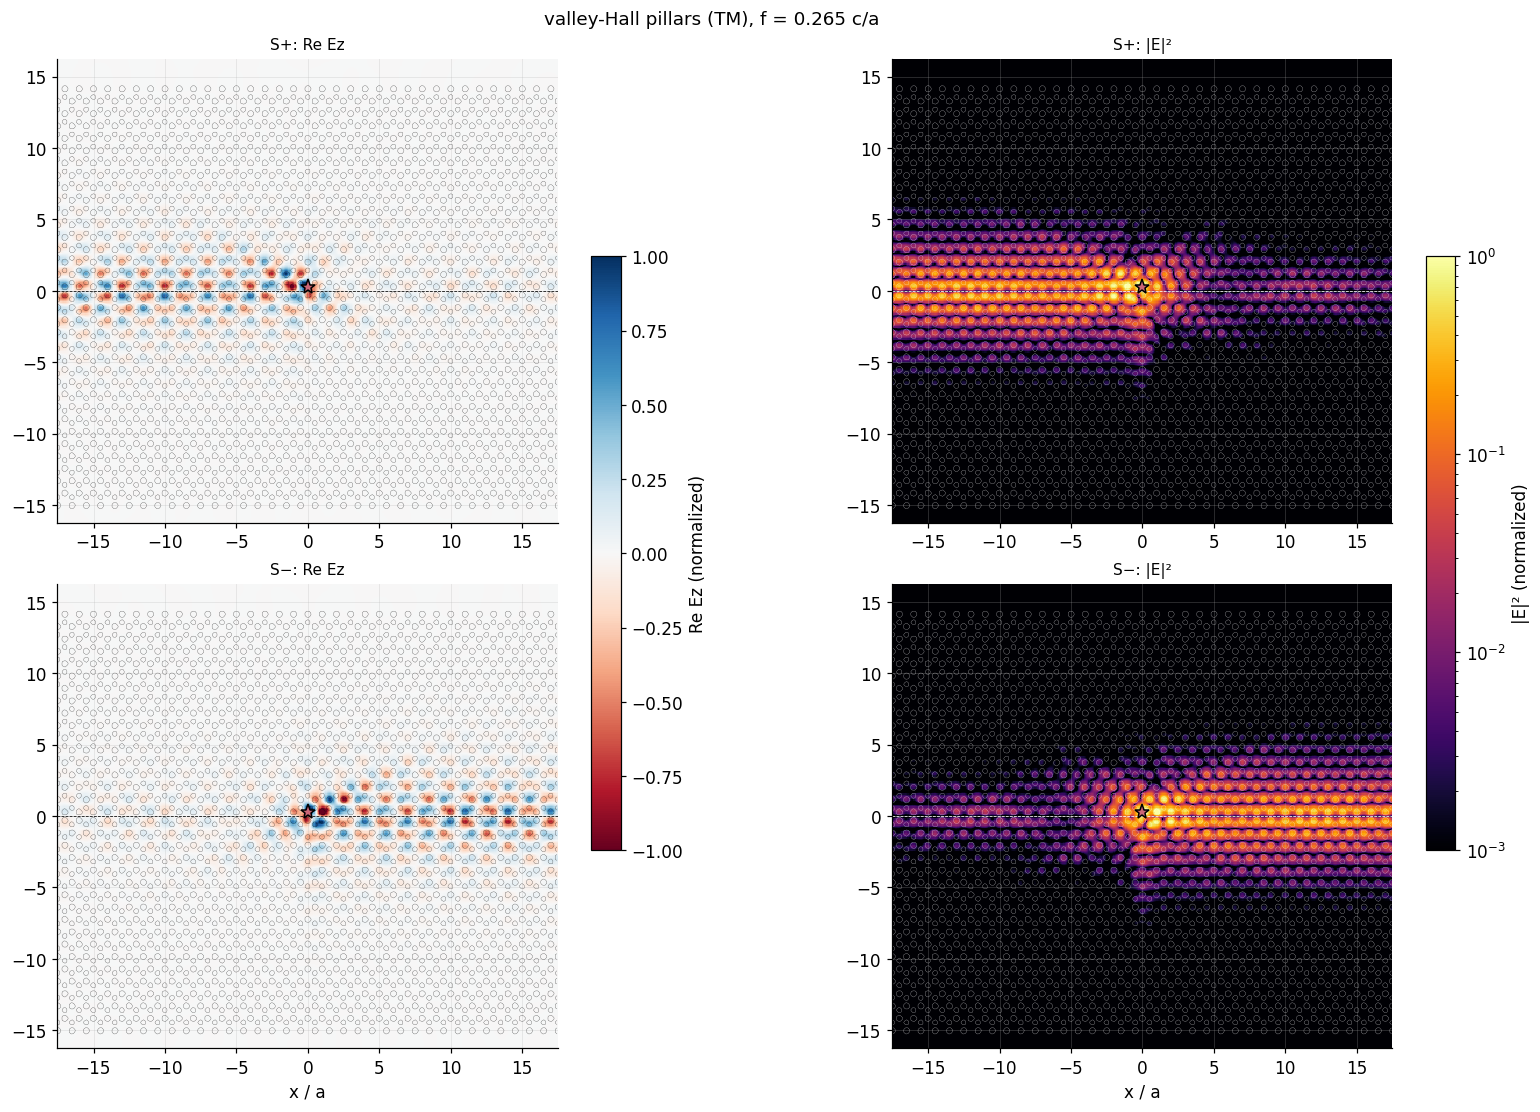

In [6]:
field_figure("valley_tm")

## 3. Directionality

Power through a closed box around the source (vertical lines 8 a0 / 14 a from the source
along the wall, horizontal lines just inside the PML across it), evaluated at full
resolution. η = (P_left − P_right)/(P_left + P_right). The samples are mirror-symmetric
about the vertical line through the source, and that mirror swaps S+ and S−, so
P_left(S+) = P_right(S−) checks the numerics.

In [7]:
# Power split for every wall and handedness.
print(f"{'wall':>26} {'src':>4} {'P_left':>8} {'P_right':>8} {'through bulk':>13} {'η':>8} {'mirror check':>13}")
for kind in tp.KINDS:
    o = {s: load(kind, s) for s in (+1, -1)}
    for s in (+1, -1):
        P = {k: float(o[s][f"P_{k}"]) for k in ("left", "right", "top", "bottom")}
        tot = sum(P.values())
        eta = (P["left"] - P["right"]) / (P["left"] + P["right"])
        chk = f"{float(o[+1]['P_left'] / o[-1]['P_right']):.4f}" if s > 0 else ""
        print(f"{TITLE[kind]:>26} {'S+' if s > 0 else 'S−':>4} {P['left'] / tot:>8.3f} {P['right'] / tot:>8.3f} "
              f"{(P['top'] + P['bottom']) / tot:>13.3f} {eta:>+8.3f} {chk:>13}")

                      wall  src   P_left  P_right  through bulk        η  mirror check
    spin-Hall pillars (TM)   S+    0.990    0.003         0.007   +0.994        1.0000
    spin-Hall pillars (TM)   S−    0.003    0.990         0.007   -0.994              
      spin-Hall holes (TE)   S+    0.767    0.071         0.163   +0.831        1.0000
      spin-Hall holes (TE)   S−    0.071    0.767         0.163   -0.831              


    valley-Hall holes (TE)   S+    0.976    0.012         0.012   +0.975        0.9993
    valley-Hall holes (TE)   S−    0.012    0.976         0.012   -0.975              
  valley-Hall pillars (TM)   S+    0.947    0.053         0.000   +0.894        1.0000
  valley-Hall pillars (TM)   S−    0.053    0.947         0.000   -0.894              


## 4. A source at a twofold-rotation centre (valley-Hall holes)

The same S± dipole placed at the centre of the hexagon of holes on the bearded wall, a
point about which the wall is C2-symmetric.

In [8]:
# Valley-Hall holes, source at the hexagon centre on the wall.
for s in (+1, -1):
    o = load("valley_te", s, "hexcentre")
    P = {k: float(o[f"P_{k}"]) for k in ("left", "right", "top", "bottom")}
    tot = sum(P.values())
    print(f"hexagon centre, {'S+' if s > 0 else 'S−'}: P_left {P['left'] / tot:.3f}, P_right {P['right'] / tot:.3f}, "
          f"η = {(P['left'] - P['right']) / (P['left'] + P['right']):+.4f}")

hexagon centre, S+: P_left 0.494, P_right 0.494, η = +0.0001


hexagon centre, S−: P_left 0.494, P_right 0.494, η = -0.0001


## 5. Summary

- **One-way excitation on all four walls.** S+ sends the power left and S− right on every
  wall; the mirror check P_left(S+) = P_right(S−) holds to 0.1 %.
- **Directionality** η = 0.994 (spin-Hall pillars), 0.975 (valley-Hall holes), 0.894
  (valley-Hall pillars), 0.831 (spin-Hall holes). The spin-Hall hole wall also loses 16 % of
  the power through the bulk crystals: its shared gap is only ≈ 3 %, so the bulk fields
  decay slowly; the other walls lose ≤ 1.2 %.
- **Source position matters for valley-Hall.** In a bearded inclusion the valley sources
  are directional; at the hexagon centre on the wall, a twofold-rotation centre, the same
  sources split the power exactly evenly (η = 10⁻⁴).
- The valley-Hall walls guide their edge states near K with gaps of 6.8 % (holes) and 8.7 %
  (pillars), against 3–4 % for the spin-Hall gaps, and confine the light more tightly to the
  wall at comparable sample size.